# Assignment 56 — Week 7, Day 2
## Topic: Machine Learning — Neural Networks from Scratch

**Objective:** Demonstrate neural networks.

**Reference:** https://www.analyticsvidhya.com/blog/2020/07/neural-networks-from-scratch-in-python-and-r

A neural network is made of layers of **neurons**. Each neuron multiplies its inputs by **weights**, adds a **bias**, and passes the result through an **activation function**. Training means adjusting the weights so the network's output matches the target.

Following the Analytics Vidhya article, this notebook builds a small network **using only NumPy**, so every step of the maths is visible:

1. **Forward propagation** – compute the output from the inputs.
2. **Error** – compare the output with the target.
3. **Backward propagation** – work out how much each weight contributed to the error.
4. **Update** – adjust the weights a little in the direction that reduces the error (gradient descent).

**Diagram:** Every input is connected to every hidden neuron, and every hidden neuron to the output.

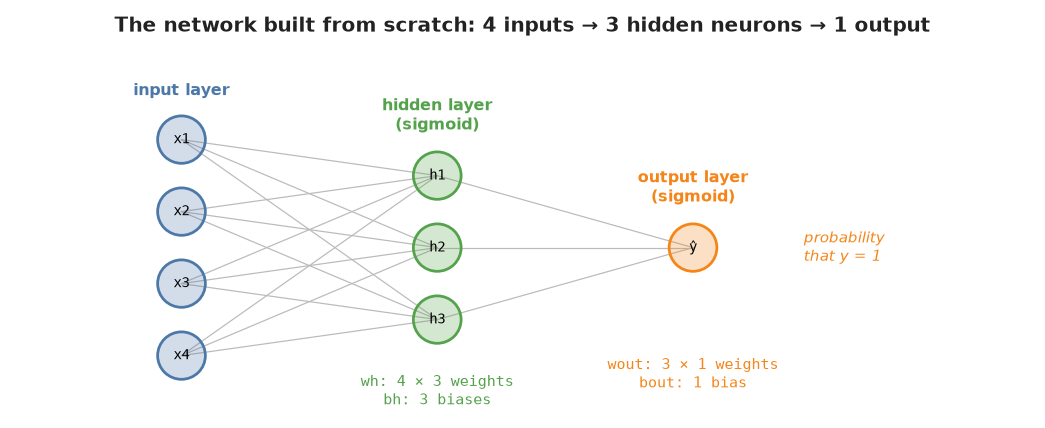

**The input data and target**

In [1]:
import numpy as np

# Each row is one example with 4 input features
X = np.array([[1, 0, 1, 0],
              [1, 0, 1, 1],
              [0, 1, 0, 1]])

# Target output for each example
y = np.array([[1], [1], [0]])

print("X shape:", X.shape)
print(X)
print("y (targets):", y.ravel())

X shape: (3, 4)
[[1 0 1 0]
 [1 0 1 1]
 [0 1 0 1]]
y (targets): [1 1 0]


**Explanation:** There are 3 examples, each with 4 binary input features. The network must learn to output 1 for the first two examples and 0 for the third.

**The sigmoid activation function and its derivative**

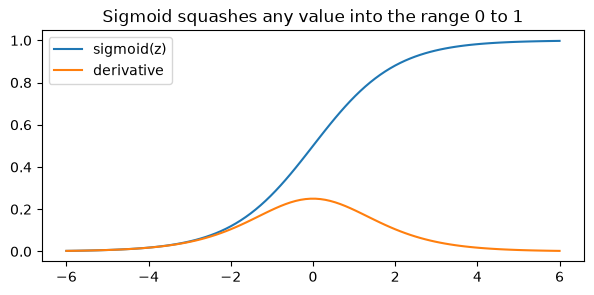

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def derivatives_sigmoid(x):
    # x is already a sigmoid output
    return x * (1 - x)

z = np.linspace(-6, 6, 100)
plt.figure(figsize=(7, 3))
plt.plot(z, sigmoid(z), label="sigmoid(z)")
plt.plot(z, derivatives_sigmoid(sigmoid(z)), label="derivative")
plt.legend()
plt.title("Sigmoid squashes any value into the range 0 to 1")
plt.show()

**Explanation:** The sigmoid turns any number into a value between 0 and 1. Its derivative, sigmoid × (1 − sigmoid), is needed during backward propagation to measure how sensitive each neuron is.

**Initialise the weights and biases**

In [3]:
import numpy as np

np.random.seed(42)

inputlayer_neurons = 4    # number of features
hiddenlayer_neurons = 3   # neurons in the hidden layer
output_neurons = 1        # one output

wh = np.random.uniform(size=(inputlayer_neurons, hiddenlayer_neurons))
bh = np.random.uniform(size=(1, hiddenlayer_neurons))
wout = np.random.uniform(size=(hiddenlayer_neurons, output_neurons))
bout = np.random.uniform(size=(1, output_neurons))

print("wh shape:", wh.shape, "| bh shape:", bh.shape)
print("wout shape:", wout.shape, "| bout shape:", bout.shape)

wh shape: (4, 3) | bh shape: (1, 3)
wout shape: (3, 1) | bout shape: (1, 1)


**Explanation:** The weights start as small random numbers. wh connects the 4 inputs to the 3 hidden neurons, and wout connects the 3 hidden neurons to the output.

**Diagram:** The four steps that make up one training iteration (epoch).

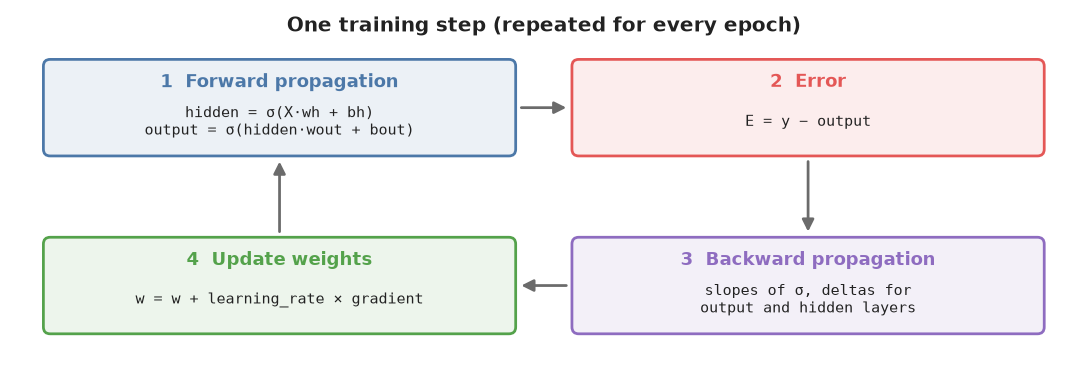

**One forward pass before training**

In [4]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X = np.array([[1, 0, 1, 0], [1, 0, 1, 1], [0, 1, 0, 1]])
y = np.array([[1], [1], [0]])

np.random.seed(42)
wh = np.random.uniform(size=(4, 3)); bh = np.random.uniform(size=(1, 3))
wout = np.random.uniform(size=(3, 1)); bout = np.random.uniform(size=(1, 1))

hidden_layer_input = np.dot(X, wh) + bh
hiddenlayer_activations = sigmoid(hidden_layer_input)
output_layer_input = np.dot(hiddenlayer_activations, wout) + bout
output = sigmoid(output_layer_input)

print("Output before training:", output.ravel().round(3))
print("Target:                ", y.ravel())

Output before training: [0.781 0.794 0.767]
Target:                 [1 1 0]


**Explanation:** With random weights, every output is close to the same value and does not match the target yet.

**Train the network with forward and backward propagation**

In [5]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def derivatives_sigmoid(x):
    return x * (1 - x)

X = np.array([[1, 0, 1, 0], [1, 0, 1, 1], [0, 1, 0, 1]])
y = np.array([[1], [1], [0]])

np.random.seed(42)
wh = np.random.uniform(size=(4, 3)); bh = np.random.uniform(size=(1, 3))
wout = np.random.uniform(size=(3, 1)); bout = np.random.uniform(size=(1, 1))

epoch = 5000   # number of training iterations
lr = 0.1       # learning rate
losses = []

for i in range(epoch):
    # 1. Forward propagation
    hidden_layer_input = np.dot(X, wh) + bh
    hiddenlayer_activations = sigmoid(hidden_layer_input)
    output_layer_input = np.dot(hiddenlayer_activations, wout) + bout
    output = sigmoid(output_layer_input)

    # 2. Error
    E = y - output
    losses.append(np.mean(E ** 2))

    # 3. Backward propagation
    slope_output_layer = derivatives_sigmoid(output)
    slope_hidden_layer = derivatives_sigmoid(hiddenlayer_activations)
    d_output = E * slope_output_layer
    Error_at_hidden_layer = d_output.dot(wout.T)
    d_hiddenlayer = Error_at_hidden_layer * slope_hidden_layer

    # 4. Update weights and biases
    wout += hiddenlayer_activations.T.dot(d_output) * lr
    bout += np.sum(d_output, axis=0, keepdims=True) * lr
    wh += X.T.dot(d_hiddenlayer) * lr
    bh += np.sum(d_hiddenlayer, axis=0, keepdims=True) * lr

print("Output after training:", output.ravel().round(3))
print("Target:               ", y.ravel())
print("Predicted classes:    ", (output.ravel() >= 0.5).astype(int))

Output after training: [0.984 0.975 0.036]
Target:                [1 1 0]
Predicted classes:     [1 1 0]


**Explanation:** Each epoch runs the four steps. The error at the output is passed back through the network (backpropagation) to find how each weight should change, and the weights are nudged by learning_rate × gradient. After 5000 epochs the outputs are close to 1, 1 and 0.

**Plot the training loss**

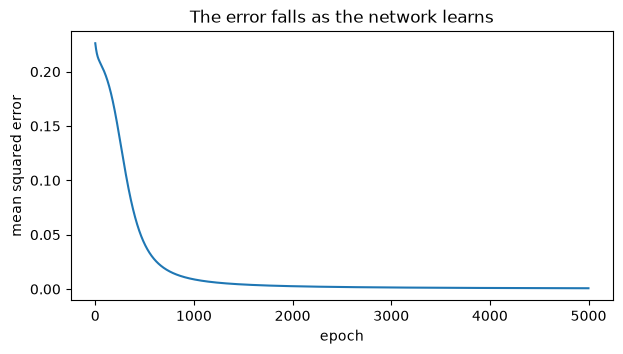

Loss at epoch 1: 0.2261 | at epoch 5000: 0.0007


In [6]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X = np.array([[1, 0, 1, 0], [1, 0, 1, 1], [0, 1, 0, 1]])
y = np.array([[1], [1], [0]])
np.random.seed(42)
wh = np.random.uniform(size=(4, 3)); bh = np.random.uniform(size=(1, 3))
wout = np.random.uniform(size=(3, 1)); bout = np.random.uniform(size=(1, 1))

losses = []
for i in range(5000):
    h = sigmoid(X.dot(wh) + bh)
    out = sigmoid(h.dot(wout) + bout)
    E = y - out
    losses.append(np.mean(E ** 2))
    d_out = E * out * (1 - out)
    d_h = d_out.dot(wout.T) * h * (1 - h)
    wout += h.T.dot(d_out) * 0.1; bout += d_out.sum(axis=0, keepdims=True) * 0.1
    wh += X.T.dot(d_h) * 0.1; bh += d_h.sum(axis=0, keepdims=True) * 0.1

plt.figure(figsize=(7, 3.5))
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.title("The error falls as the network learns")
plt.show()
print("Loss at epoch 1:", round(losses[0], 4), "| at epoch 5000:", round(losses[-1], 4))

**Explanation:** The loss (mean squared error) drops quickly at first and then levels off as the weights settle. This curve is the usual way to check that a network is learning.

**Use the trained network on a new example**

In [7]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X = np.array([[1, 0, 1, 0], [1, 0, 1, 1], [0, 1, 0, 1]])
y = np.array([[1], [1], [0]])
np.random.seed(42)
wh = np.random.uniform(size=(4, 3)); bh = np.random.uniform(size=(1, 3))
wout = np.random.uniform(size=(3, 1)); bout = np.random.uniform(size=(1, 1))
for i in range(5000):
    h = sigmoid(X.dot(wh) + bh); out = sigmoid(h.dot(wout) + bout)
    d_out = (y - out) * out * (1 - out); d_h = d_out.dot(wout.T) * h * (1 - h)
    wout += h.T.dot(d_out) * 0.1; bout += d_out.sum(axis=0, keepdims=True) * 0.1
    wh += X.T.dot(d_h) * 0.1; bh += d_h.sum(axis=0, keepdims=True) * 0.1

def predict(x):
    return sigmoid(sigmoid(np.array(x).dot(wh) + bh).dot(wout) + bout).item()

for sample in ([1, 0, 1, 0], [0, 1, 0, 1], [1, 0, 0, 0], [0, 1, 1, 1]):
    print(sample, "->", round(predict(sample), 3))

[1, 0, 1, 0] -> 0.984
[0, 1, 0, 1] -> 0.036
[1, 0, 0, 0] -> 0.926
[0, 1, 1, 1] -> 0.175


**Explanation:** After training, the network can be used on any input. It gives high outputs for inputs like the first two training examples (where x1 is 1) and a low output for the third. Inputs it has never seen get outputs based on the patterns it learned.

## Observation

- A neuron computes a weighted sum of its inputs plus a bias and passes it through an activation function such as the sigmoid.
- Forward propagation sends the inputs through the layers to produce an output.
- Backward propagation passes the error back through the network to find each weight's gradient.
- Gradient descent updates every weight by learning rate × gradient, and repeating this lowers the loss.
- After 5000 epochs the small network reproduces the targets 1, 1 and 0.

## Conclusion

Building a neural network from scratch shows that it is just matrix multiplications, activation functions and repeated small weight updates. Libraries such as Keras and PyTorch automate exactly these steps for much larger networks.